# BTC limit-order-book benchmark

Six limit-order-book models are trained and tested on one fixed dataset: Binance BTCUSDT perpetual snapshots (10 levels, every 250 ms) from Jan 9 to 20 2023, split chronologically into 9 training days, 1 validation day and 2 test days. Every model predicts the mean mid-price return over the next 0.25 to 5 seconds (1, 2, 4, 8 and 20 snapshots), at snapshots where the mid-price just moved, and is scored as a three-class direction call and as a return correlation. Each model is trained with three seeds, and the tables report mean ± std over seeds. Protocol, model settings and deviations from the papers are in the [README](README.md).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import HORIZONS, SPLITS, load_book, samples
from training import train

STEP_S = 0.25
TICK_SIZE = 0.1

## Data

The raw CSV is parsed here into `data/processed/`, and training reads from there. A gap longer than 500 ms between snapshots starts a new segment, and no input window or target crosses a segment or a UTC day.

In [2]:
RAW = "data/raw/1-09-1-20.csv"
COLUMNS = [str(p) for level in range(10) for p in (22 + 2 * level, 23 + 2 * level, 2 + 2 * level, 3 + 2 * level)]
MAX_GAP_NS = 500_000_000

frame = pd.read_csv(RAW, usecols=["0", *COLUMNS], dtype={"0": "int64", **{c: "float64" for c in COLUMNS}})
book = frame[COLUMNS].to_numpy()
book[:, 0::2] = np.rint(book[:, 0::2] / TICK_SIZE)
timestamps = frame["0"].to_numpy() * 1_000_000
segments = np.cumsum(np.r_[True, np.diff(timestamps) > MAX_GAP_NS], dtype=np.int32)
Path("data/processed").mkdir(parents=True, exist_ok=True)
np.save("data/processed/book.npy", book.astype(np.float32))
np.save("data/processed/timestamps.npy", timestamps)
np.save("data/processed/segments.npy", segments)

In [3]:
book, timestamps, segments = load_book()
mid = book[:, 0].astype(np.int64) + book[:, 2].astype(np.int64)
steps = np.diff(timestamps)
rows_per_day = pd.Series(timestamps.astype("datetime64[ns]").astype("datetime64[D]")).value_counts().sort_index()
rows_per_day.index = rows_per_day.index.strftime("%b %d")
display(pd.Series({
    "snapshots": f"{len(book):,}",
    "period (UTC)": f"{pd.Timestamp(int(timestamps[0])):%Y-%m-%d %H:%M} to {pd.Timestamp(int(timestamps[-1])):%Y-%m-%d %H:%M}",
    "segments": segments[-1],
    "exact 250 ms steps": f"{(steps == 250_000_000).mean():.1%}",
    "mid moves": f"{(np.diff(mid) != 0).mean():.1%} of snapshots",
}).to_frame("").T)
display(rows_per_day.to_frame("rows").T)

,snapshots,period (UTC),segments,exact 250 ms steps,mid moves
,"3,730,870",2023-01-09 22:17 to 2023-01-20 18:10,297,59.4%,16.3% of snapshots


,Jan 09,Jan 10,Jan 11,Jan 12,Jan 13,Jan 14,Jan 15,Jan 16,Jan 17,Jan 18,Jan 19,Jan 20
rows,24499,344799,344339,344549,344628,344616,344607,344447,344479,344454,344488,260965


In [4]:
splits, theta = samples()
train_labels = splits["train"][1]
display(pd.DataFrame({
    "theta": theta,
    "down": (train_labels == 0).mean(0),
    "stationary": (train_labels == 1).mean(0),
    "up": (train_labels == 2).mean(0),
}, index=pd.Index([h * STEP_S for h in HORIZONS], name="horizon (s)")).style.format({"theta": "{:.2e}", "down": "{:.1%}", "stationary": "{:.1%}", "up": "{:.1%}"}))
display(pd.Series({split: f"{len(s[0]):,}" for split, s in splits.items()}, name="samples").to_frame().T)

,theta,down,stationary,up
horizon (s),,,,
0.250000,0.00e+00,23.3%,53.7%,22.9%
0.500000,0.00e+00,29.9%,40.8%,29.3%
1.000000,7.24e-06,33.6%,33.3%,33.0%
2.000000,2.29e-05,33.6%,33.3%,33.1%
5.000000,4.68e-05,33.6%,33.3%,33.1%


,train,validation,test
samples,"455,089","79,006","67,537"


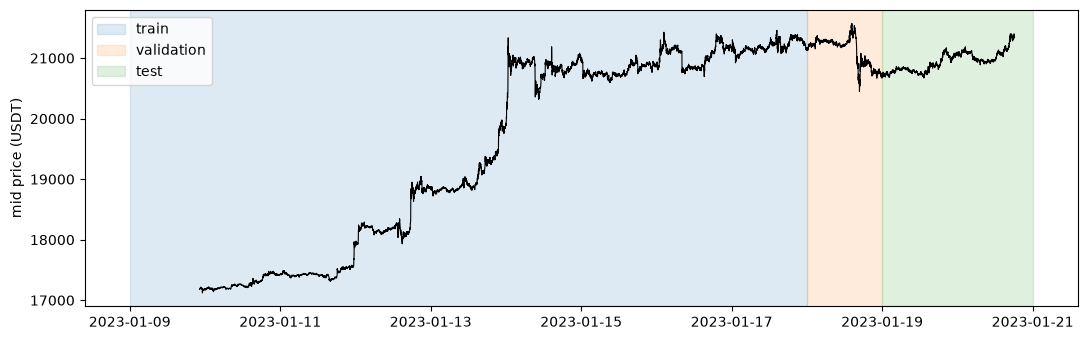

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(pd.to_datetime(np.asarray(timestamps[::240])), (book[::240, 0] + book[::240, 2]) / 2 * TICK_SIZE, lw=0.8, color="black")
for (split, (start, end)), color in zip(SPLITS.items(), ("tab:blue", "tab:orange", "tab:green")):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1), color=color, alpha=0.15, label=split)
ax.set_ylabel("mid price (USDT)")
ax.legend(loc="upper left")
plt.tight_layout()

## Models

Each cell trains one model for every seed and horizon group, or loads the runs already saved in `runs/`.

In [6]:
results = {}

### DeepLOB

Zhang et al. 2019: convolutions over the z-scored book, an inception module and an LSTM. One network per horizon.

In [7]:
results["deeplob"] = train("deeplob")

### Multi-horizon DeepLOB

Zhang & Zohren 2021: the DeepLOB encoder with an attention LSTM decoder that emits all five horizons in sequence. One network for all horizons.

In [8]:
results["multihorizon_deeplob"] = train("multihorizon_deeplob")

### TLOB

Berti & Kasneci 2025: bilinear normalisation and a transformer with attention over both features and time, evaluated on an exponential moving average of the weights. One network per horizon.

In [9]:
results["tlob"] = train("tlob")

### Deep OFI LSTM

Kolm et al. 2023: an LSTM on order-flow imbalance with a linear head that regresses all five horizons. One network for all horizons.

In [10]:
results["deepofi_lstm"] = train("deepofi_lstm")

### Siamese LSTM

Yang et al. 2025: one LSTM shared by the bid and ask order flow, regressing a bounded return. One network per horizon.

In [11]:
results["siamese_lstm"] = train("siamese_lstm")

### Custom symmetric LOB

This project's own model: a shared bid/ask encoder with exact mirror averaging, dilated causal convolutions over time, slow-context averages over 30 s to 10 min, multi-horizon decoding, and class and return heads. One network for all horizons.

In [12]:
results["custom_symmetric_lob"] = train("custom_symmetric_lob")

## Results

Mean ± std over the three seeds on the two test days. Regressors are classified with the same per-horizon θ as the classifiers. At 0.25 s and 0.5 s θ = 0, which a regressor never predicts exactly, so compare the two groups by Pearson there.

In [13]:
df = pd.concat(results.values(), ignore_index=True)
df["horizon (s)"] = df["horizon"] * STEP_S


def pm(frame, metric, by, fmt="{:.3f}"):
    g = frame.groupby(by, sort=False)[metric].agg(["mean", "std"])
    return g["mean"].map(fmt.format) + " ± " + g["std"].map(fmt.format)


def table(frame, metric, fmt="{:.3f}"):
    return pm(frame, metric, ["model", "horizon (s)"], fmt).unstack("horizon (s)").reindex(frame["model"].unique())

Macro-F1 by model and horizon.

In [14]:
table(df, "macro_f1")

horizon (s),0.25,0.50,1.00,2.00,5.00
model,,,,,
deeplob,0.655 ± 0.003,0.673 ± 0.002,0.647 ± 0.001,0.605 ± 0.003,0.555 ± 0.002
multihorizon_deeplob,0.644 ± 0.020,0.668 ± 0.006,0.645 ± 0.002,0.603 ± 0.002,0.551 ± 0.003
tlob,0.604 ± 0.004,0.641 ± 0.005,0.620 ± 0.003,0.580 ± 0.001,0.533 ± 0.003
deepofi_lstm,0.323 ± 0.000,0.386 ± 0.001,0.456 ± 0.003,0.509 ± 0.002,0.474 ± 0.005
siamese_lstm,0.276 ± 0.012,0.370 ± 0.001,0.540 ± 0.001,0.492 ± 0.010,0.401 ± 0.022
custom_symmetric_lob,0.670 ± 0.000,0.682 ± 0.001,0.658 ± 0.000,0.620 ± 0.001,0.566 ± 0.000


Pearson correlation between the model's score (up minus down probability for classifiers, the predicted return for regressors) and the realised return.

In [15]:
table(df, "pearson")

horizon (s),0.25,0.50,1.00,2.00,5.00
model,,,,,
deeplob,0.423 ± 0.000,0.440 ± 0.001,0.445 ± 0.001,0.440 ± 0.001,0.407 ± 0.001
multihorizon_deeplob,0.419 ± 0.001,0.438 ± 0.000,0.445 ± 0.002,0.435 ± 0.004,0.403 ± 0.004
tlob,0.408 ± 0.001,0.427 ± 0.001,0.434 ± 0.000,0.426 ± 0.002,0.395 ± 0.002
deepofi_lstm,0.363 ± 0.003,0.390 ± 0.005,0.401 ± 0.003,0.395 ± 0.002,0.367 ± 0.001
siamese_lstm,0.257 ± 0.001,0.298 ± 0.002,0.369 ± 0.001,0.389 ± 0.002,0.371 ± 0.000
custom_symmetric_lob,0.425 ± 0.000,0.452 ± 0.000,0.467 ± 0.001,0.459 ± 0.001,0.421 ± 0.001


Models that predict returns: out-of-sample R² against the test-set mean (Kolm et al.), and mean absolute error.

In [16]:
regressors = df.dropna(subset=["r2_os"])
pd.concat({"R²_OS": table(regressors, "r2_os"), "MAE": table(regressors, "mae", "{:.2e}")}, axis=1)

R²_OS                                \
horizon (s)                    0.25           0.50           1.00   
model                                                               
deepofi_lstm          0.122 ± 0.006  0.143 ± 0.008  0.153 ± 0.006   
siamese_lstm          0.042 ± 0.002  0.073 ± 0.002  0.120 ± 0.001   
custom_symmetric_lob  0.208 ± 0.000  0.232 ± 0.002  0.236 ± 0.002   

                                                                    MAE  \
horizon (s)                    2.00           5.00                 0.25   
model                                                                     
deepofi_lstm          0.151 ± 0.004  0.131 ± 0.001  2.21e-05 ± 3.50e-07   
siamese_lstm          0.145 ± 0.003  0.136 ± 0.001  1.67e-05 ± 7.30e-09   
custom_symmetric_lob  0.222 ± 0.003  0.182 ± 0.002  1.93e-05 ± 1.16e-07   

                                                                \
horizon (s)                          0.50                 1.00   
model                                                            
deepofi_lstm          2.62e-05 ± 4.27e-07  3.32e-05 ± 3.93e-07   
siamese_lstm          2.18e-05 ± 1.48e-08  3.02e-05 ± 1.54e-08   
custom_symmetric_lob  2.28e-05 ± 1.23e-07  2.97e-05 ± 1.16e-07   

                                                                
horizon (s)                          2.00                 5.00  
model                                                           
deepofi_lstm          4.44e-05 ± 3.04e-07  6.96e-05 ± 1.14e-07  
siamese_lstm          4.27e-05 ± 7.85e-08  6.86e-05 ± 9.61e-08  
custom_symmetric_lob  4.10e-05 ± 4.31e-08  6.60e-05 ± 4.13e-08

Stability across the two test days, averaged over seeds.

In [17]:
daily = pd.DataFrame([{"model": r.model, "horizon (s)": r.horizon * STEP_S, "day": day, **v}
                      for r in df.itertuples() for day, v in r.per_day.items()])
daily.pivot_table(index=["model", "horizon (s)"], columns="day", values=["macro_f1", "pearson"]).loc[df["model"].unique()].round(3)

macro_f1               pearson           
day                              2023-01-19 2023-01-20 2023-01-19 2023-01-20
model                horizon (s)                                            
deeplob              0.25             0.658      0.652      0.432      0.412
                     0.50             0.675      0.669      0.451      0.427
                     1.00             0.648      0.645      0.456      0.432
                     2.00             0.603      0.607      0.449      0.430
                     5.00             0.552      0.558      0.418      0.396
multihorizon_deeplob 0.25             0.649      0.639      0.428      0.408
                     0.50             0.669      0.666      0.448      0.426
                     1.00             0.645      0.644      0.456      0.432
                     2.00             0.602      0.605      0.445      0.423
                     5.00             0.548      0.554      0.415      0.389
tlob                 0.25             0.606      0.601      0.418      0.396
                     0.50             0.642      0.639      0.437      0.416
                     1.00             0.618      0.622      0.443      0.424
                     2.00             0.576      0.586      0.435      0.417
                     5.00             0.529      0.537      0.406      0.384
deepofi_lstm         0.25             0.324      0.323      0.372      0.351
                     0.50             0.386      0.387      0.398      0.379
                     1.00             0.454      0.458      0.409      0.391
                     2.00             0.506      0.512      0.402      0.387
                     5.00             0.477      0.470      0.375      0.358
siamese_lstm         0.25             0.277      0.275      0.270      0.242
                     0.50             0.371      0.370      0.311      0.281
                     1.00             0.542      0.538      0.382      0.353
                     2.00             0.500      0.481      0.399      0.377
                     5.00             0.410      0.389      0.380      0.360
custom_symmetric_lob 0.25             0.673      0.666      0.436      0.412
                     0.50             0.685      0.679      0.464      0.439
                     1.00             0.657      0.658      0.478      0.455
                     2.00             0.617      0.623      0.469      0.448
                     5.00             0.564      0.568      0.434      0.406

Cost per trained network: parameters, epochs run, and wall-clock training minutes (the saved runs shared each A100 between several jobs).

In [18]:
runs = df.drop_duplicates(["model", "seed", "minutes"])
pd.DataFrame({
    "parameters": runs.groupby("model", sort=False)["parameters"].first().map("{:,}".format),
    "epochs": pm(runs, "epochs", "model", "{:.1f}"),
    "minutes": pm(runs, "minutes", "model", "{:.1f}"),
})

,parameters,epochs,minutes
model,,,
deeplob,"142,435",44.7 ± 9.6,191.5 ± 34.9
multihorizon_deeplob,"177,059",50.0 ± 0.0,220.8 ± 18.8
tlob,"1,135,971",4.6 ± 1.0,10.3 ± 2.9
deepofi_lstm,"76,933",23.0 ± 4.4,13.1 ± 3.1
siamese_lstm,"98,433",21.1 ± 5.8,16.2 ± 4.2
custom_symmetric_lob,"281,908",15.0 ± 0.0,30.9 ± 0.1


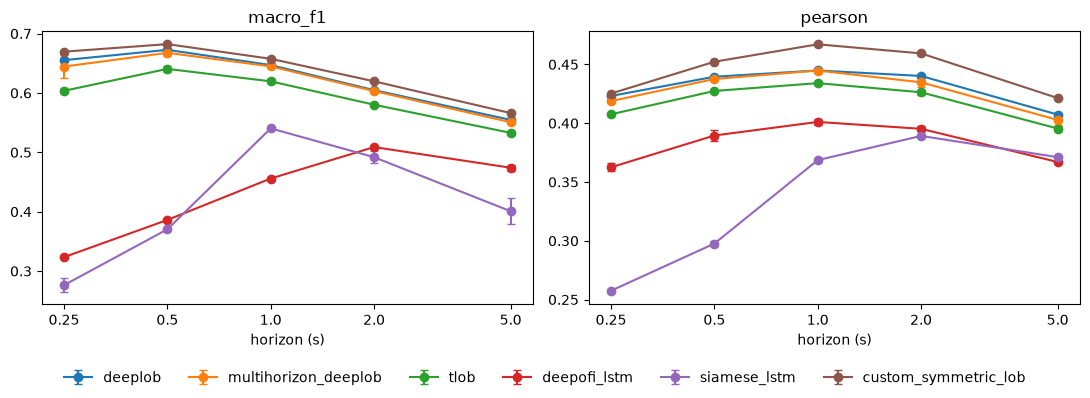

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ("macro_f1", "pearson")):
    for model, g in df.groupby("model", sort=False):
        s = g.groupby("horizon (s)")[metric].agg(["mean", "std"])
        ax.errorbar(s.index, s["mean"], s["std"], marker="o", capsize=3, label=model)
    ax.set_xscale("log")
    ax.set_xticks(df["horizon (s)"].unique(), df["horizon (s)"].unique())
    ax.minorticks_off()
    ax.set_xlabel("horizon (s)")
    ax.set_title(metric)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=6, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))

## Findings

- **The custom model is best at every horizon**, from 0.670 macro-F1 at 0.25 s to 0.566 at 5 s. It beats DeepLOB in all 15 seed–horizon pairs, by 0.010 to 0.015 on average.
- **Its return head is the best return forecast**: Pearson 0.42 to 0.49, above every baseline classifier's score at each horizon (at most 0.445), and R²_OS of 0.18 to 0.24, against 0.04 to 0.15 for the two pure regressors.
- **One multi-horizon DeepLOB matches five single-horizon DeepLOBs**, within 0.01 macro-F1 at every horizon. TLOB trails both by 0.02 to 0.05, with its upstream early stopping ending after 3 to 6 epochs.
- **The order-flow regressors (Deep OFI, Siamese) are weakest.** Their low F1 at 0.25 s and 0.5 s is partly the θ = 0 artefact, but they also trail the classifiers on Pearson at every horizon.
- **Predictability peaks at 0.5 to 1 s and fades by 5 s.** The ranking holds on both test days and across seeds; the standard deviation is at most 0.006 except for multi-horizon DeepLOB at 0.25 s and Siamese.